In [74]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

In [75]:
folder = Path("../data/raw_data/")
print(folder.exists())

True


In [76]:
csv_files = sorted(folder.glob("*.csv"))
print(len(csv_files))
for file in csv_files:
    print(file.name)

4
active_power_03to05_2026.csv
active_power_06to08_2026.csv
active_power_12_2025to02_2026.csv
active_power_9to11_2025.csv


In [77]:
dfs = {}
for f in csv_files:
    dfs[f.name] = pd.read_csv(f)

print(dfs.keys())

dict_keys(['active_power_03to05_2026.csv', 'active_power_06to08_2026.csv', 'active_power_12_2025to02_2026.csv', 'active_power_9to11_2025.csv'])


In [78]:
for name, df in dfs.items():
    print("="*60)
    print(name)
    print(df.dtypes)
    print("NaN counts: ")
    print(df.isna().sum())

active_power_03to05_2026.csv
Data                        str
P. Ativa Fund+Harm      float64
P. Ativa Fund+Harm A    float64
P. Ativa Fund+Harm B    float64
P. Ativa Fund+Harm C    float64
dtype: object
NaN counts: 
Data                    0
P. Ativa Fund+Harm      0
P. Ativa Fund+Harm A    0
P. Ativa Fund+Harm B    0
P. Ativa Fund+Harm C    0
dtype: int64
active_power_06to08_2026.csv
Data                        str
P. Ativa Fund+Harm      float64
P. Ativa Fund+Harm A    float64
P. Ativa Fund+Harm B    float64
P. Ativa Fund+Harm C    float64
dtype: object
NaN counts: 
Data                    0
P. Ativa Fund+Harm      2
P. Ativa Fund+Harm A    2
P. Ativa Fund+Harm B    2
P. Ativa Fund+Harm C    2
dtype: int64
active_power_12_2025to02_2026.csv
Data                        str
P. Ativa Fund+Harm      float64
P. Ativa Fund+Harm A    float64
P. Ativa Fund+Harm B    float64
P. Ativa Fund+Harm C    float64
dtype: object
NaN counts: 
Data                    0
P. Ativa Fund+Harm      0
P. Ativa 

In [79]:
df = pd.concat(list(dfs.values()), ignore_index=True)
df.shape

(8755, 5)

In [80]:
df["Data"] = pd.to_datetime(df["Data"], format="%d/%m/%Y %H:%M:%S")
df.dtypes

Data                    datetime64[us]
P. Ativa Fund+Harm             float64
P. Ativa Fund+Harm A           float64
P. Ativa Fund+Harm B           float64
P. Ativa Fund+Harm C           float64
dtype: object

In [81]:
df = df.set_index("Data").sort_index()
df.head()

,P. Ativa Fund+Harm,P. Ativa Fund+Harm A,P. Ativa Fund+Harm B,P. Ativa Fund+Harm C
Data,,,,
2025-09-01 00:00:00,1880.60,628.24,568.31,684.05
2025-09-01 01:00:00,1915.08,656.36,568.84,689.88
2025-09-01 02:00:00,1911.84,628.01,591.19,692.64
2025-09-01 03:00:00,1905.20,636.66,575.93,692.61
2025-09-01 04:00:00,1904.15,649.34,565.06,689.75


In [82]:
df.columns = ["total", "phase_a", "phase_b", "phase_c"]
df.index.name = "timestamp"
df.head()

,total,phase_a,phase_b,phase_c
timestamp,,,,
2025-09-01 00:00:00,1880.60,628.24,568.31,684.05
2025-09-01 01:00:00,1915.08,656.36,568.84,689.88
2025-09-01 02:00:00,1911.84,628.01,591.19,692.64
2025-09-01 03:00:00,1905.20,636.66,575.93,692.61
2025-09-01 04:00:00,1904.15,649.34,565.06,689.75


In [83]:
df = df.drop(columns=["phase_a", "phase_b", "phase_c"])
df.head()

,total
timestamp,
2025-09-01 00:00:00,1880.60
2025-09-01 01:00:00,1915.08
2025-09-01 02:00:00,1911.84
2025-09-01 03:00:00,1905.20
2025-09-01 04:00:00,1904.15


In [84]:
print("Shape: ", df.shape)
print("Min Date: ", df.index.min())
print("Max Date: ", df.index.max())
print("Unique: ", df.index.is_unique)
print("Unique: ", df.index.duplicated().sum())
print("NaN values: ", df.isna().sum())


Shape:  (8755, 1)
Min Date:  2025-09-01 00:00:00
Max Date:  2026-08-31 23:00:00
Unique:  True
Unique:  0
NaN values:  total    3
dtype: int64


In [85]:
full_index = pd.date_range(df.index.min(), df.index.max(), freq="h")
print(len(full_index))

8760


In [86]:
missing_rows = full_index.difference(df.index)
print(len(missing_rows))
print(missing_rows)

8
DatetimeIndex(['2025-10-17 07:00:00', '2025-10-17 08:00:00',
               '2026-06-21 15:00:00', '2026-06-21 16:00:00',
               '2026-07-19 11:00:00', '2026-07-19 12:00:00',
               '2026-07-19 13:00:00', '2026-07-19 14:00:00'],
              dtype='datetime64[us]', freq=None)


In [87]:
df_full = df.reindex(full_index)
df_full.index.name = "timestamp"

print("Shape: ", df_full.shape) 
print(df_full["total"].isna().sum()) 

gaps = df_full[df_full["total"].isna()]
print(gaps)

Shape:  (8760, 1)
8
                     total
timestamp                 
2025-10-17 07:00:00    NaN
2025-10-17 08:00:00    NaN
2026-06-21 15:00:00    NaN
2026-06-21 16:00:00    NaN
2026-07-19 11:00:00    NaN
2026-07-19 12:00:00    NaN
2026-07-19 13:00:00    NaN
2026-07-19 14:00:00    NaN


In [88]:
summary = pd.DataFrame({
    "timestamp": gaps.index,
    "day_name": gaps.index.day_name(),
    "hour": gaps.index.hour,
    "was_row_missing": gaps.index.isin(missing_rows)
    
})

summary

,timestamp,day_name,hour,was_row_missing
0,2025-10-17 07:00:00,Friday,7,True
1,2025-10-17 08:00:00,Friday,8,True
2,2026-06-21 15:00:00,Sunday,15,True
3,2026-06-21 16:00:00,Sunday,16,True
4,2026-07-19 11:00:00,Sunday,11,True
5,2026-07-19 12:00:00,Sunday,12,True
6,2026-07-19 13:00:00,Sunday,13,True
7,2026-07-19 14:00:00,Sunday,14,True


In [89]:
print(len(df), df["total"].isna().sum())

8755 3


In [90]:
clusters = [
    ("2025-10-17 07:00", "2025-10-17 08:00"),
    ("2026-06-21 15:00", "2026-06-21 16:00"),
    ("2026-07-19 11:00", "2026-07-19 14:00")
]

for start, end in clusters:
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    before = start - pd.Timedelta(hours=3)
    after = end + pd.Timedelta(hours=3)

    print("="*80)
    print(f"Gap: {start} to {end}")
    print(df_full.loc[before:after, "total"])

    for w in (-1,1):
        shift = pd.Timedelta(weeks=w)
        print(f"\nSame hours, {w:+d} week:")
        print(df_full.loc[before + shift :after + shift, "total"])
        




Gap: 2025-10-17 07:00:00 to 2025-10-17 08:00:00
timestamp
2025-10-17 04:00:00    3646.13
2025-10-17 05:00:00    3517.65
2025-10-17 06:00:00    3270.18
2025-10-17 07:00:00        NaN
2025-10-17 08:00:00        NaN
2025-10-17 09:00:00    7824.82
2025-10-17 10:00:00    7556.91
2025-10-17 11:00:00    7494.34
Freq: h, Name: total, dtype: float64

Same hours, -1 week:
timestamp
2025-10-10 04:00:00     3197.46
2025-10-10 05:00:00     3149.30
2025-10-10 06:00:00     3370.46
2025-10-10 07:00:00     4856.72
2025-10-10 08:00:00    10871.31
2025-10-10 09:00:00    14180.04
2025-10-10 10:00:00    15328.56
2025-10-10 11:00:00    17376.30
Freq: h, Name: total, dtype: float64

Same hours, +1 week:
timestamp
2025-10-24 04:00:00     3257.22
2025-10-24 05:00:00     3160.42
2025-10-24 06:00:00     3252.80
2025-10-24 07:00:00     7031.43
2025-10-24 08:00:00    18969.17
2025-10-24 09:00:00    26608.24
2025-10-24 10:00:00    32036.87
2025-10-24 11:00:00    34247.24
Freq: h, Name: total, dtype: float64
Gap: 20

In [91]:
df_clean = df_full.copy()
df_clean["is_imputed"] = df_clean["total"].isna()

In [92]:
df_clean["total"] = df_clean["total"].interpolate(method="time")
print(df_clean["total"].isna().sum())
print(df_clean["is_imputed"].sum())
print(df_clean.loc[df_clean["is_imputed"], "total"])

0
8
timestamp
2025-10-17 07:00:00    4788.393333
2025-10-17 08:00:00    6306.606667
2026-06-21 15:00:00    4638.240000
2026-06-21 16:00:00    4833.240000
2026-07-19 11:00:00    3062.466000
2026-07-19 12:00:00    3078.282000
2026-07-19 13:00:00    3094.098000
2026-07-19 14:00:00    3109.914000
Name: total, dtype: float64


In [93]:
neg = df_clean[df_clean["total"]< 0]
print(len(neg))

print(df_clean.loc[df_clean["total"] == 0].sum())

0
total         0.0
is_imputed    0.0
dtype: float64


In [94]:
print(df_clean["total"].describe())
print(df_clean["total"].nlargest(10))
print(df_clean["total"].diff().abs().nlargest(10))

count     8760.000000
mean      7560.246695
std       8162.062164
min       1275.430000
25%       2331.605000
50%       3604.000000
75%      10186.415000
max      63789.500000
Name: total, dtype: float64
timestamp
2026-03-03 14:00:00    63789.50
2026-03-04 14:00:00    60720.18
2026-03-05 14:00:00    60135.26
2026-04-01 14:00:00    58565.64
2025-11-28 14:00:00    55905.96
2026-03-03 13:00:00    54441.77
2025-12-08 09:00:00    53662.11
2026-03-04 13:00:00    52894.06
2026-03-03 15:00:00    52111.89
2026-03-30 14:00:00    52072.93
Name: total, dtype: float64
timestamp
2025-12-08 08:00:00    32723.25
2026-03-30 08:00:00    31140.25
2025-12-08 16:00:00    30050.39
2026-03-04 13:00:00    28383.66
2026-03-05 18:00:00    26500.15
2026-02-05 17:00:00    25816.51
2026-04-01 13:00:00    25529.25
2026-03-30 12:00:00    22515.64
2026-01-15 10:00:00    22452.45
2026-02-11 17:00:00    22056.53
Name: total, dtype: float64


In [95]:
same = df_clean["total"].diff() == 0
print(df_clean[df_clean["total"].diff() == 0])

                       total  is_imputed
timestamp                               
2025-11-20 11:00:00  3022.68       False


In [96]:
df_clean[df_clean["total"] == 3022.68]

,total,is_imputed
timestamp,,
2025-11-20 10:00:00,3022.68,False
2025-11-20 11:00:00,3022.68,False


In [97]:
df_clean["total"] = df_clean["total"]/1000

In [98]:
print(df_clean.head())
print(df.head())

                       total  is_imputed
timestamp                               
2025-09-01 00:00:00  1.88060       False
2025-09-01 01:00:00  1.91508       False
2025-09-01 02:00:00  1.91184       False
2025-09-01 03:00:00  1.90520       False
2025-09-01 04:00:00  1.90415       False
                       total
timestamp                   
2025-09-01 00:00:00  1880.60
2025-09-01 01:00:00  1915.08
2025-09-01 02:00:00  1911.84
2025-09-01 03:00:00  1905.20
2025-09-01 04:00:00  1904.15


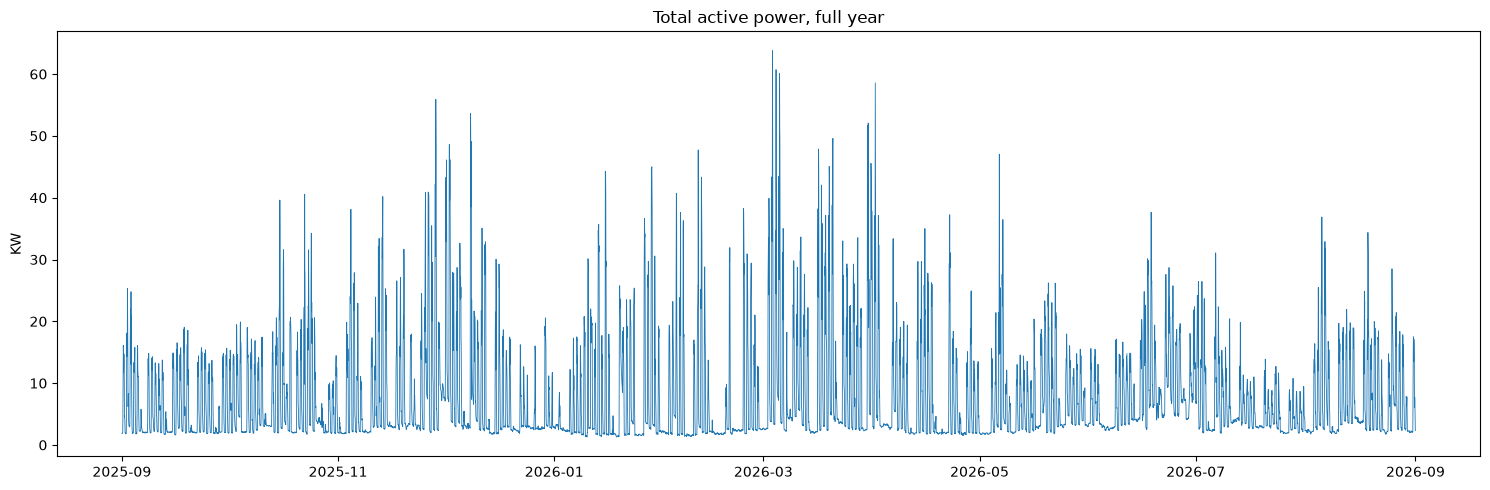

In [102]:
fig, ax = plt.subplots(figsize=(15,5))
ax.plot(df_clean.index, df_clean["total"], linewidth=0.6)
ax.set_title("Total active power, full year")
ax.set_ylabel("KW")
plt.tight_layout()
plt.savefig("../plots/full_data_plot.png")
plt.show()

In [104]:
by_hr = df_clean.groupby(df_clean.index.hour)["total"].mean()
by_dow = df_clean.groupby(df_clean.index.day_name())["total"].mean()
by_month = df_clean.groupby(df_clean.index.to_period("M"))["total"].mean()
print(by_hr)
print(by_dow)
print(by_month)

timestamp
0      2.925464
1      2.917630
2      2.907574
3      2.900144
4      2.875349
5      2.834217
6      2.890873
7      4.994959
8     10.360080
9     13.425828
10    14.732933
11    14.289147
12    12.082426
13    14.047159
14    15.517259
15    14.532405
16    12.349938
17     8.541185
18     6.212736
19     5.354227
20     4.759063
21     3.959225
22     3.099234
23     2.936864
Name: total, dtype: float64
timestamp
Friday       8.039011
Monday       9.181107
Saturday     4.002912
Sunday       2.904651
Thursday     9.063499
Tuesday      9.746666
Wednesday    9.952710
Name: total, dtype: float64
timestamp
2025-09     5.877046
2025-10     7.182181
2025-11     8.680101
2025-12     7.929121
2026-01     7.005117
2026-02     6.404154
2026-03    12.002459
2026-04     7.079501
2026-05     6.737884
2026-06     8.689217
2026-07     5.674749
2026-08     7.352288
Freq: M, Name: total, dtype: float64


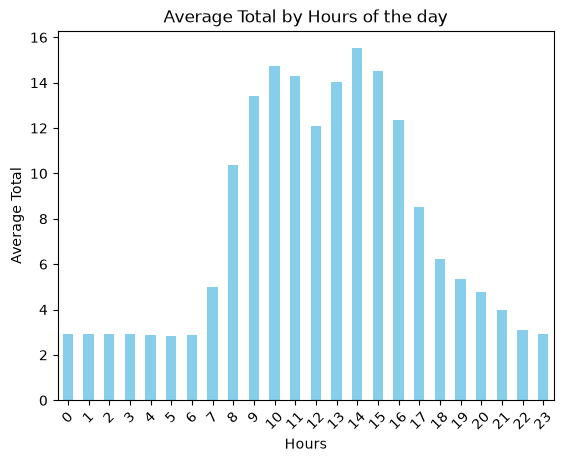

In [ ]:
by_hr.plot(kind="bar", color="skyblue")
plt.title('Average Total by Hours of the day')
plt.xlabel('Hours')
plt.ylabel('Average Total')
plt.xticks(rotation=45)

plt.savefig('../plots/hourly_average_total.png', dpi=300, bbox_inches='tight')
plt.show()


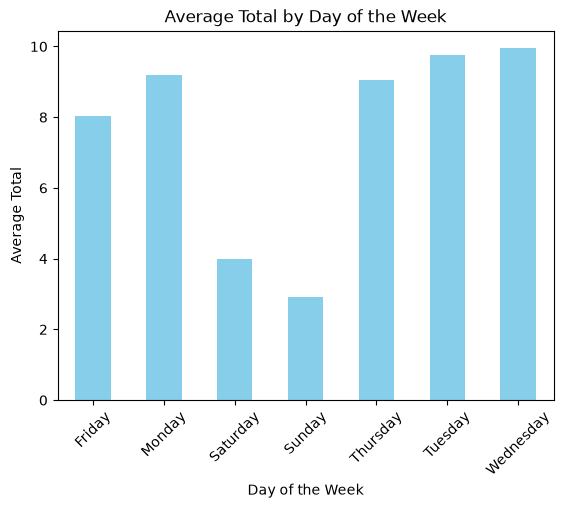

In [ ]:
by_dow.plot(kind="bar", color="skyblue")
plt.title('Average Total by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Average Total')
plt.xticks(rotation=45)

plt.savefig('../plots/dow_average_total.png', dpi=300, bbox_inches='tight')
plt.show()

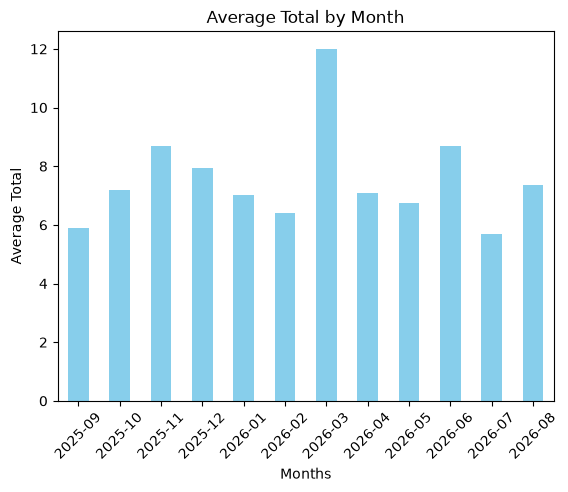

In [ ]:
by_month.plot(kind="bar", color="skyblue")
plt.title('Average Total by Month')
plt.xlabel('Months')
plt.ylabel('Average Total')
plt.xticks(rotation=45)

plt.savefig('../plots/monthly_average_total.png', dpi=300, bbox_inches='tight')
plt.show()

In [109]:
print(df_clean.groupby(df_clean.index.to_period("M"))["total"].agg(["min", "max"]))

               min       max
timestamp                   
2025-09    1.61614  25.31446
2025-10    1.71832  40.56181
2025-11    1.78910  55.90596
2025-12    1.74215  53.66211
2026-01    1.27543  45.00211
2026-02    1.36739  47.72149
2026-03    1.85173  63.78950
2026-04    1.51081  58.56564
2026-05    1.68379  47.05039
2026-06    2.29913  37.65273
2026-07    1.82040  31.07330
2026-08    1.75496  36.87391


In [110]:
df_final = df_clean.copy()
df_final.head()

,total,is_imputed
timestamp,,
2025-09-01 00:00:00,1.88060,False
2025-09-01 01:00:00,1.91508,False
2025-09-01 02:00:00,1.91184,False
2025-09-01 03:00:00,1.90520,False
2025-09-01 04:00:00,1.90415,False


In [111]:
df_final.to_csv("../data/processed_data.csv")